# 01 · ¿Qué se asocia con el valor de las viviendas de California?
**The Hatch C1 — análisis exploratorio simple y reproducible.**

Fuente: [California Housing Prices, camnugent, Kaggle](https://www.kaggle.com/datasets/camnugent/california-housing-prices).
Enfoque adaptado del [notebook de Katherine Varela](https://github.com/katherinevarela775/C1DS-Price_Analysis/blob/main/notebooks/house_prices.ipynb):
diagnóstico de topes, imputación, ratios y comparación entre datos preparados y curados.
Datos del censo de **1990**; una fila es una zona censal con valores agregados, no una vivienda individual.
El valor objetivo es la mediana del valor de las viviendas de esa zona, en USD históricos.
`median_income` es un índice de ingreso escalado, no un salario literal en dólares.

Preguntas: ¿cómo se distribuyen los precios? ¿Qué relación tienen con ingreso y costa?
¿La ubicación y las habitaciones por hogar aportan contexto?
Seguimos el orden obligatorio: exploración → limpieza → análisis simple → análisis complejo.
No necesitamos un modelo predictivo para responder estas preguntas de EDA.

## Cómo ejecutar este notebook
Entregable autocontenido: solo necesitás este `.ipynb`, un kernel Python con pip y conexión a internet.
Reiniciá el kernel y ejecutá todas las celdas de arriba abajo.
La primera celda instala librerías faltantes; la siguiente descarga el ZIP público de Kaggle
y lee el archivo en memoria. No necesita `data/`, `scripts/`, `docs/`, `memory/` ni `outputs/`.
Los resultados y gráficos quedan dentro del notebook, sin crear CSV ni carpetas de salida.

Verificado con Python 3.11, Pandas 2.2.3, NumPy 2.1.3, Matplotlib 3.9.4 y Seaborn 0.13.2.
Para Brasil también se utiliza python-calamine 0.3.1 para leer el Excel.
En Kaggle, habilitá internet para ejecutar y vinculá el dataset correspondiente al publicar.
Una revisión del dataset puede cambiar los resultados; se imprime el hash del archivo descargado.

In [1]:
# Instala en este kernel solo las librerías que falten.
import importlib.util
import subprocess
import sys

paquetes = {'pandas': 'pandas==2.2.3', 'numpy': 'numpy==2.1.3', 'matplotlib': 'matplotlib==3.9.4', 'seaborn': 'seaborn==0.13.2'}
faltantes = [paquete for modulo, paquete in paquetes.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])
print("Librerías disponibles para ejecutar el notebook.")

Librerías disponibles para ejecutar el notebook.


In [2]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 12)
SEMILLA = 42

# Descarga el dataset público de Kaggle en cada ejecución.
URL = "https://www.kaggle.com/api/v1/datasets/download/camnugent/california-housing-prices"
with urlopen(URL, timeout=90) as respuesta:
    comprimido = respuesta.read()
with ZipFile(BytesIO(comprimido)) as zip_datos:
    contenido = zip_datos.read("housing.csv")
raw = pd.read_csv(BytesIO(contenido))
print("Dataset:", "camnugent/california-housing-prices")
print("Archivo:", "housing.csv", "| Filas y columnas:", raw.shape)
print("SHA-256:", hashlib.sha256(contenido).hexdigest())

def mostrar():
    plt.tight_layout()
    plt.show()
    plt.close("all")

Dataset: camnugent/california-housing-prices
Archivo: housing.csv | Filas y columnas: (20640, 10)
SHA-256: 8a3727f4cf54ac1a327f69b1d5b4db54c5834ea81c6e4efc0d163300022a685e


## 1. Exploración de las características
Primero vemos cómo son los datos originales. `info` describe tipos y valores presentes;
`describe` muestra centro, dispersión y extremos; `isna` cuenta faltantes.

| Columna | Significado / unidad |
|---|---|
| longitude / latitude | Coordenadas de la zona, grados |
| housing_median_age | Edad mediana de las viviendas, años |
| total_rooms / total_bedrooms | Habitaciones / dormitorios totales de la zona |
| population / households | Personas / hogares de la zona |
| median_income | Ingreso mediano escalado |
| median_house_value | Valor mediano de las viviendas, USD de 1990 |
| ocean_proximity | Categoría de cercanía al océano; no distancia numérica |

In [3]:
display(raw.head())
raw.info()
display(raw.describe().round(2))
nulos = pd.DataFrame({"cantidad": raw.isna().sum(), "porcentaje": raw.isna().mean() * 100})
display(nulos.round(2))
print("Filas exactamente duplicadas:", raw.duplicated().sum())
display(raw["ocean_proximity"].value_counts().rename("zonas"))
topes = pd.DataFrame({
    "maximo": raw[["median_house_value", "housing_median_age", "median_income"]].max(),
    "zonas_en_maximo": raw[["median_house_value", "housing_median_age", "median_income"]].eq(
        raw[["median_house_value", "housing_median_age", "median_income"]].max()).sum(),
})
topes["porcentaje"] = topes["zonas_en_maximo"] / len(raw) * 100
display(topes.round(3))

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.00,20640.00,20640.00,20640.00,20433.00,20640.00,20640.00,20640.00,20640.00
mean,-119.57,35.63,28.64,2635.76,537.87,1425.48,499.54,3.87,206855.82
std,2.00,2.14,12.59,2181.62,421.39,1132.46,382.33,1.90,115395.62
min,-124.35,32.54,1.00,2.00,1.00,3.00,1.00,0.50,14999.00
25%,-121.80,33.93,18.00,1447.75,296.00,787.00,280.00,2.56,119600.00
50%,-118.49,34.26,29.00,2127.00,435.00,1166.00,409.00,3.53,179700.00
75%,-118.01,37.71,37.00,3148.00,647.00,1725.00,605.00,4.74,264725.00
max,-114.31,41.95,52.00,39320.00,6445.00,35682.00,6082.00,15.00,500001.00


,cantidad,porcentaje
longitude,0,0.0
latitude,0,0.0
housing_median_age,0,0.0
total_rooms,0,0.0
total_bedrooms,207,1.0
population,0,0.0
households,0,0.0
median_income,0,0.0
median_house_value,0,0.0
ocean_proximity,0,0.0


Filas exactamente duplicadas: 0


ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: zonas, dtype: int64

,maximo,zonas_en_maximo,porcentaje
median_house_value,500001.0,965,4.675
housing_median_age,52.0,1273,6.168
median_income,15.0,49,0.237


## 2. Limpieza y preprocesamiento
Conservamos `raw`. No borramos zonas solo por tener los mismos valores: faltan identificadores
censales para probar duplicados reales. Si hay filas idénticas, se reportan para investigarlas.
Comprobamos denominadores positivos. Imputamos únicamente dormitorios faltantes con la mediana
global: es sencillo y poco sensible a extremos. Marcamos qué filas se imputaron.
Los outliers y los topes se conservan; pueden ser observaciones válidas o límites de medición.
Conservamos `df` como base preparada. Siguiendo el repo de referencia, creamos además `df_clean`:
precio por debajo del máximo observado y los tres ratios hasta su P99 calculado en la base completa.
Es una selección para comparar, no una prueba de que las filas excluidas sean incorrectas.
No eliminamos los topes de edad e ingreso. El filtrado cambia la población que estamos describiendo.

In [4]:
df = raw.copy()
df["ocean_proximity"] = df["ocean_proximity"].str.strip().str.upper()
assert (df[["households", "total_rooms"]] > 0).all().all(), "Revisar denominadores"
df["bedrooms_imputados"] = df["total_bedrooms"].isna()
mediana_dormitorios = df["total_bedrooms"].median()
df["total_bedrooms"] = df["total_bedrooms"].fillna(mediana_dormitorios)
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]
ratios = ["rooms_per_household", "bedrooms_per_room", "population_per_household"]
cortes_p99 = df[ratios].quantile(0.99)
sin_tope = df["median_house_value"] < df["median_house_value"].max()
ratios_en_rango = df[ratios].le(cortes_p99).all(axis=1)
df_clean = df.loc[sin_tope & ratios_en_rango].copy()
display(cortes_p99.to_frame("P99"))
auditoria = pd.Series({
    "filas_originales": len(raw), "filas_preparadas": len(df), "filas_curadas": len(df_clean),
    "filas_excluidas_curado": len(df) - len(df_clean),
    "porcentaje_excluido": (len(df) - len(df_clean)) / len(df) * 100,
    "dormitorios_imputados": int(df["bedrooms_imputados"].sum()),
    "mediana_imputacion": mediana_dormitorios,
    "valores_en_maximo_precio": int(df["median_house_value"].eq(df["median_house_value"].max()).sum()),
    "valores_en_maximo_edad": int(df["housing_median_age"].eq(df["housing_median_age"].max()).sum()),
})
display(auditoria.to_frame("resultado"))
assert not df.select_dtypes("number").isna().any().any()
assert np.isfinite(df.select_dtypes("number")).all().all()

,P99
rooms_per_household,10.357033
bedrooms_per_room,0.416530
population_per_household,5.394812


,resultado
filas_originales,20640.000000
filas_preparadas,20640.000000
filas_curadas,19087.000000
filas_excluidas_curado,1553.000000
porcentaje_excluido,7.524225
dormitorios_imputados,207.000000
mediana_imputacion,435.000000
valores_en_maximo_precio,965.000000
valores_en_maximo_edad,1273.000000


## 3. Análisis simple
### 3.1 Distribuciones individuales
Cada histograma cuenta zonas por intervalo. Una cola derecha indica que algunas zonas
tienen valores mucho mayores. El amontonamiento del precio máximo requiere cautela:
no conocemos cuánto valdrían esas zonas sin el posible tope.
Esta figura usa la base preparada completa para que el tope siga visible.

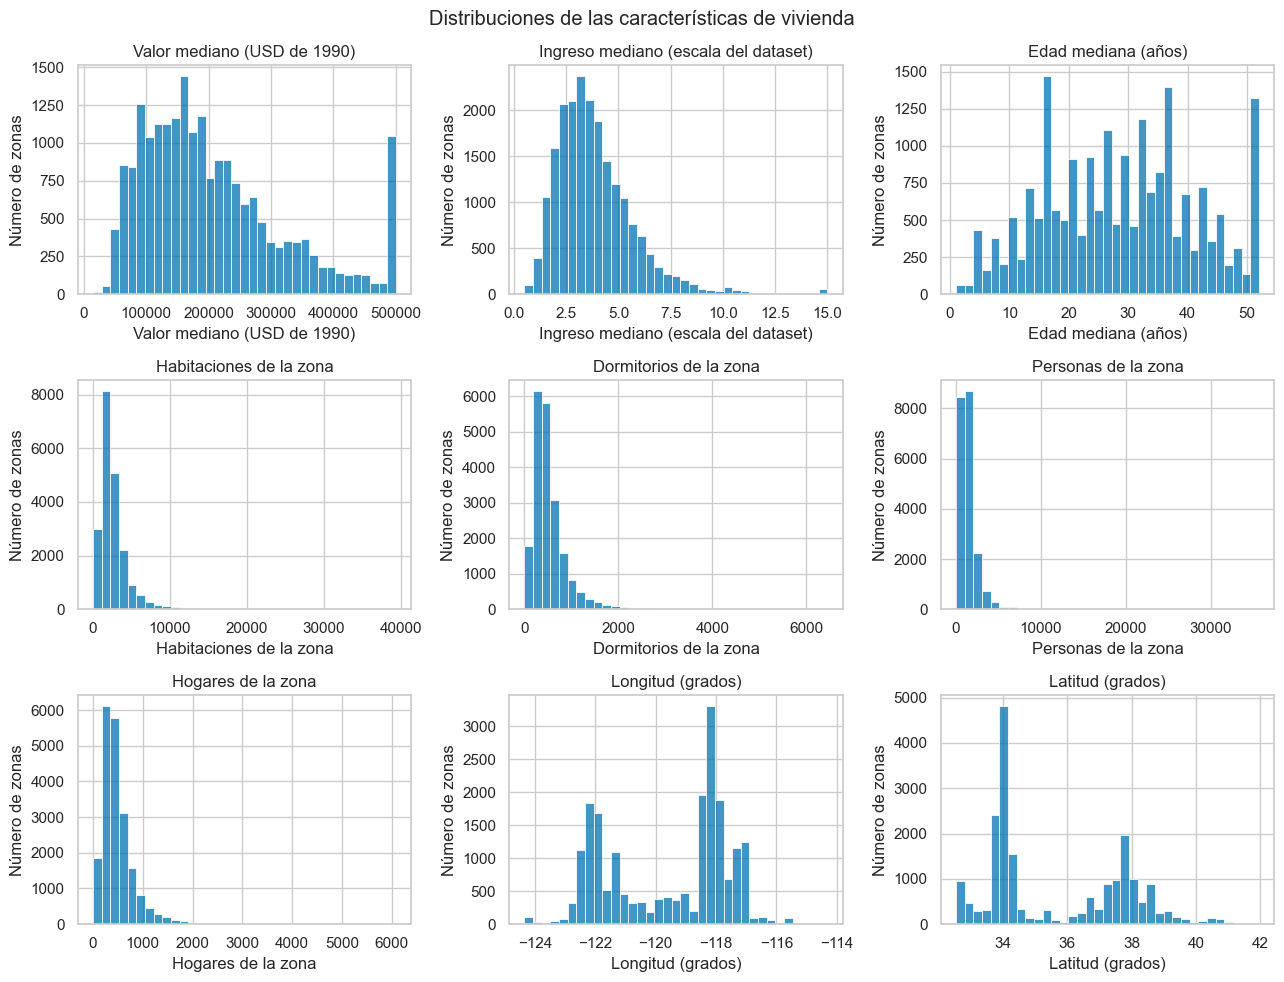

In [5]:
columnas = ["median_house_value", "median_income", "housing_median_age",
            "total_rooms", "total_bedrooms", "population", "households", "longitude", "latitude"]
etiquetas = ["Valor mediano (USD de 1990)", "Ingreso mediano (escala del dataset)",
             "Edad mediana (años)", "Habitaciones de la zona", "Dormitorios de la zona",
             "Personas de la zona", "Hogares de la zona", "Longitud (grados)", "Latitud (grados)"]
fig, ejes = plt.subplots(3, 3, figsize=(13, 10))
for columna, etiqueta, eje in zip(columnas, etiquetas, ejes.flat):
    sns.histplot(data=df, x=columna, bins=35, ax=eje)
    eje.set(xlabel=etiqueta, ylabel="Número de zonas", title=etiqueta)
fig.suptitle("Distribuciones de las características de vivienda")
mostrar()

### 3.2 Segmentación por costa y filtro por ingreso
Comparamos medianas y cantidades. El boxplot muestra Q1, mediana y Q3; los puntos
fuera de los bigotes son extremos estadísticos, no errores comprobados.
El filtro `3 ≤ ingreso < 5` compara un rango similar de ingreso, aunque no elimina toda confusión.

,count,mean,median
ocean_proximity,,,
<1H OCEAN,8362,224974.13,209150.0
INLAND,6269,122500.78,107200.0
ISLAND,5,380440.00,414700.0
NEAR BAY,2062,237454.70,220150.0
NEAR OCEAN,2389,228656.30,219500.0


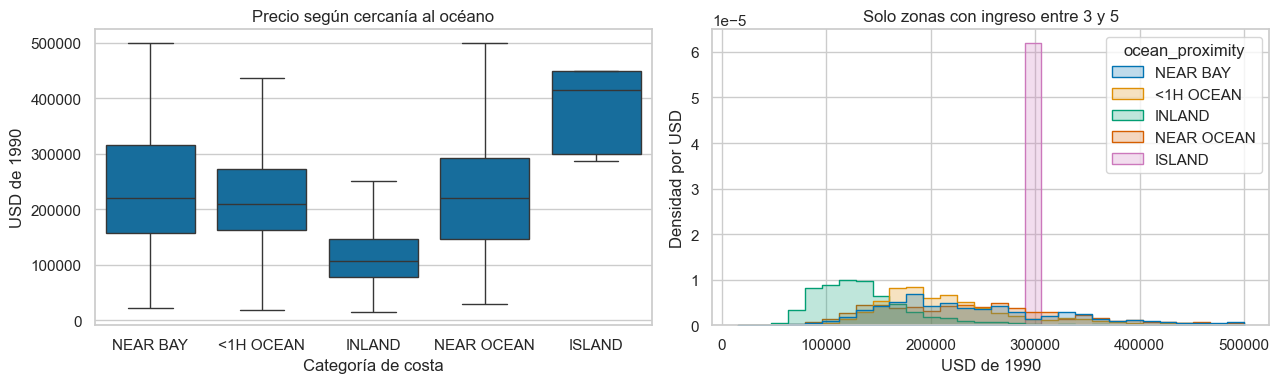

,count,median
ocean_proximity,,
<1H OCEAN,3850,202400.0
INLAND,2454,128300.0
ISLAND,1,300000.0
NEAR BAY,950,223300.0
NEAR OCEAN,1117,234600.0


In [6]:
por_costa = df_clean.groupby("ocean_proximity")["median_house_value"].agg(["count", "mean", "median"])
display(por_costa.round(2))
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df_clean, x="ocean_proximity", y="median_house_value", showfliers=False, ax=ejes[0])
ejes[0].set(title="Precio según cercanía al océano", xlabel="Categoría de costa", ylabel="USD de 1990")
comparable = df_clean.loc[df_clean["median_income"].ge(3) & df_clean["median_income"].lt(5)]
sns.histplot(data=comparable, x="median_house_value", hue="ocean_proximity",
             bins=30, element="step", stat="density", common_norm=False, ax=ejes[1])
ejes[1].set(title="Solo zonas con ingreso entre 3 y 5", xlabel="USD de 1990", ylabel="Densidad por USD")
mostrar()
display(comparable.groupby("ocean_proximity")["median_house_value"].agg(["count", "median"]).round(2))

### 3.3 Correlaciones
Pearson mide relación lineal; Spearman compara rangos. Un valor cercano a 1 indica
asociación positiva, cercano a −1 negativa y cercano a 0 poca relación de ese tipo.
Ninguno prueba causa. Usamos todas las filas para calcularlos.
Comparamos base preparada y subconjunto curado con las mismas variables.
Una correlación mayor después de filtrar no significa que hayamos descubierto la correlación verdadera.

,Pearson_base,Pearson_curado,Spearman_curado
median_house_value,1.000,1.000,1.000
median_income,0.688,0.653,0.663
housing_median_age,0.106,0.069,0.048
rooms_per_household,0.152,0.259,0.233
bedrooms_per_room,-0.233,-0.250,-0.299
population_per_household,-0.024,-0.263,-0.238


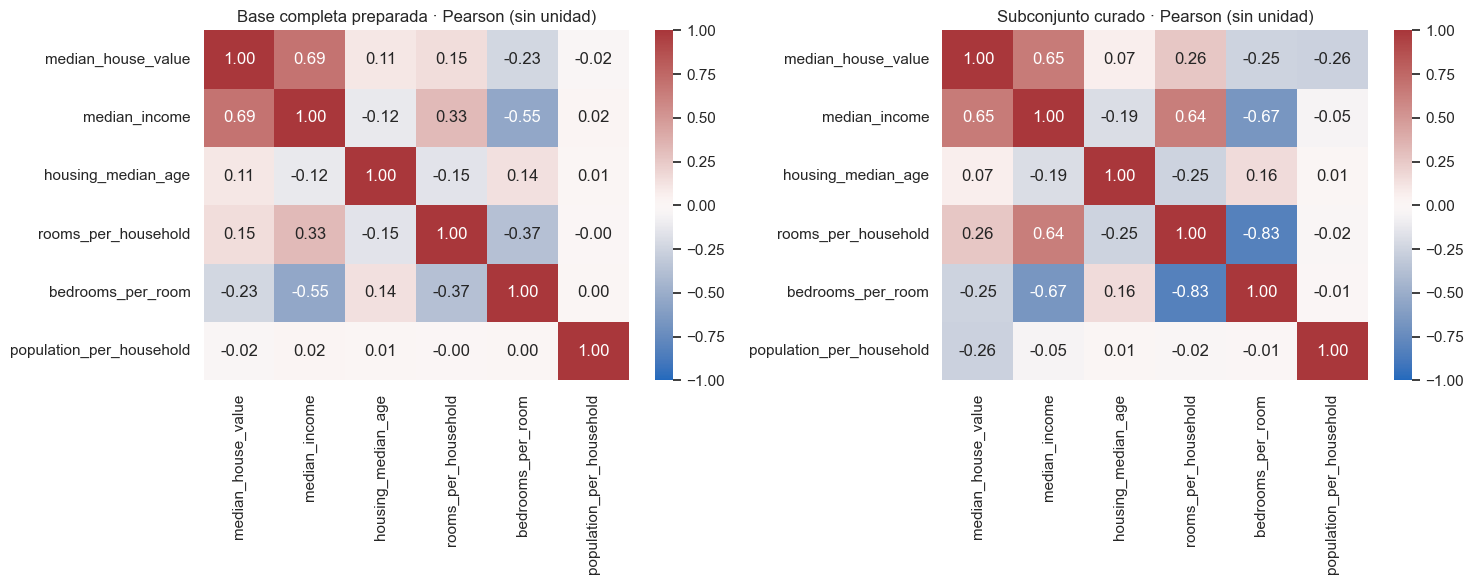

In [7]:
variables = ["median_house_value", "median_income", "housing_median_age",
             "rooms_per_household", "bedrooms_per_room", "population_per_household"]
correlaciones = df[variables].corr()
corr_clean = df_clean[variables].corr()
display(pd.DataFrame({"Pearson_base": correlaciones["median_house_value"],
                      "Pearson_curado": corr_clean["median_house_value"],
                      "Spearman_curado": df_clean[variables].corr(method="spearman")["median_house_value"]}).round(3))
fig, ejes = plt.subplots(1, 2, figsize=(15, 6))
for matriz, titulo, eje in [(correlaciones, "Base completa preparada", ejes[0]), (corr_clean, "Subconjunto curado", ejes[1])]:
    sns.heatmap(matriz, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="vlag", ax=eje)
    eje.set_title(titulo + " · Pearson (sin unidad)")
mostrar()

### 3.4 Pairplot
Reúne histogramas y dispersiones para comparar varias variables a la vez.
Mostramos hasta 800 zonas con semilla 42. Repetimos las mismas columnas y conservamos
en el segundo pairplot solo las zonas de esa muestra que pasan el filtro de curado.
Así comparamos las mismas observaciones retenidas, no dos gráficos con variables distintas.
Las estadísticas anteriores usan toda la base o todo el subconjunto, según su etiqueta.

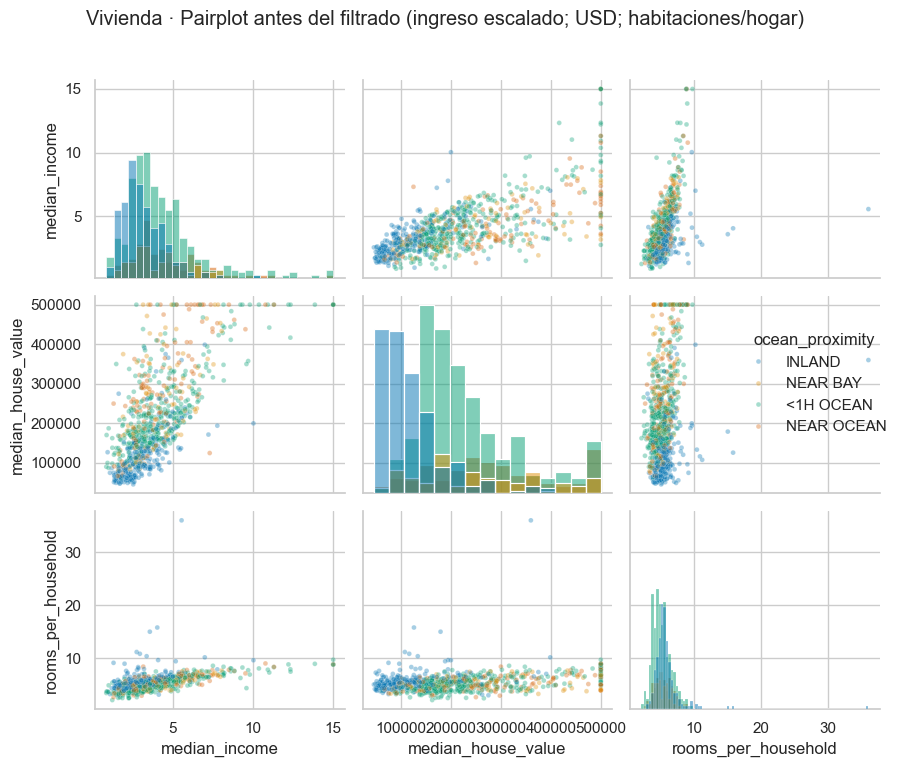

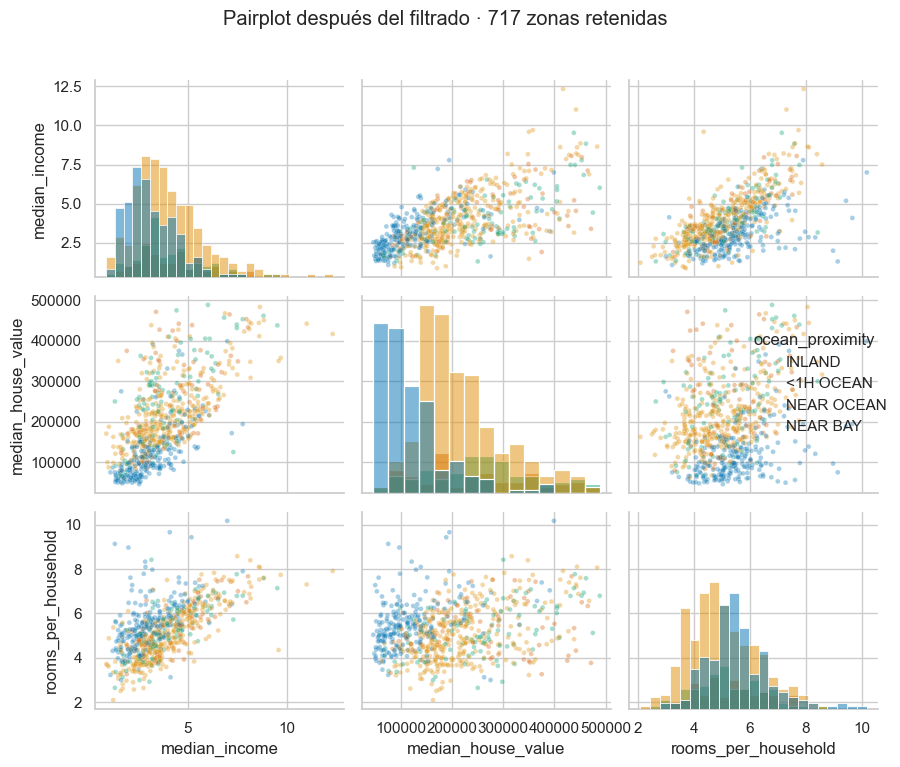

In [8]:
muestra = df.sample(n=min(800, len(df)), random_state=SEMILLA)
columnas_pair = ["median_income", "median_house_value", "rooms_per_household"]
g = sns.pairplot(muestra, vars=columnas_pair,
                 hue="ocean_proximity", diag_kind="hist", plot_kws={"alpha": 0.35, "s": 12})
g.fig.suptitle("Vivienda · Pairplot antes del filtrado (ingreso escalado; USD; habitaciones/hogar)", y=1.02)
mostrar()
muestra = muestra.loc[muestra.index.isin(df_clean.index)].copy()
g = sns.pairplot(muestra, vars=columnas_pair, hue="ocean_proximity", diag_kind="hist",
                 plot_kws={"alpha": 0.35, "s": 12})
g.fig.suptitle(f"Pairplot después del filtrado · {len(muestra)} zonas retenidas", y=1.02)
mostrar()

## 4. Análisis complejo
### 4.1 Geografía y variables derivadas
Una dispersión de longitud/latitud muestra ubicación aproximada. El color representa precio.
Habitaciones por hogar contextualiza el tamaño de cada zona; no es una medición directa
del tamaño de cada vivienda. Aquí usamos el subconjunto curado; el filtro es de filas, no solo del eje.

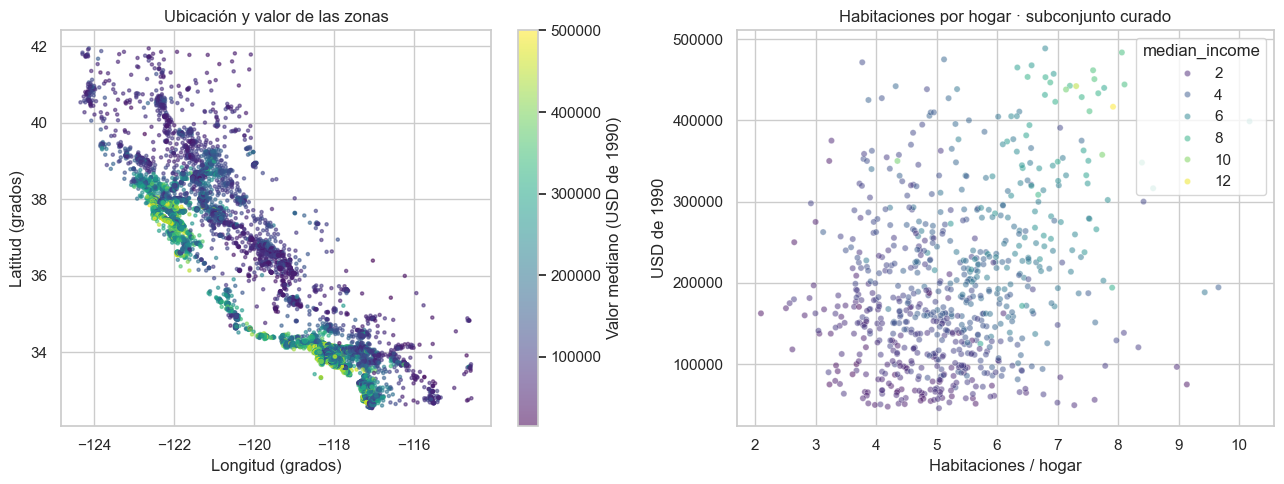

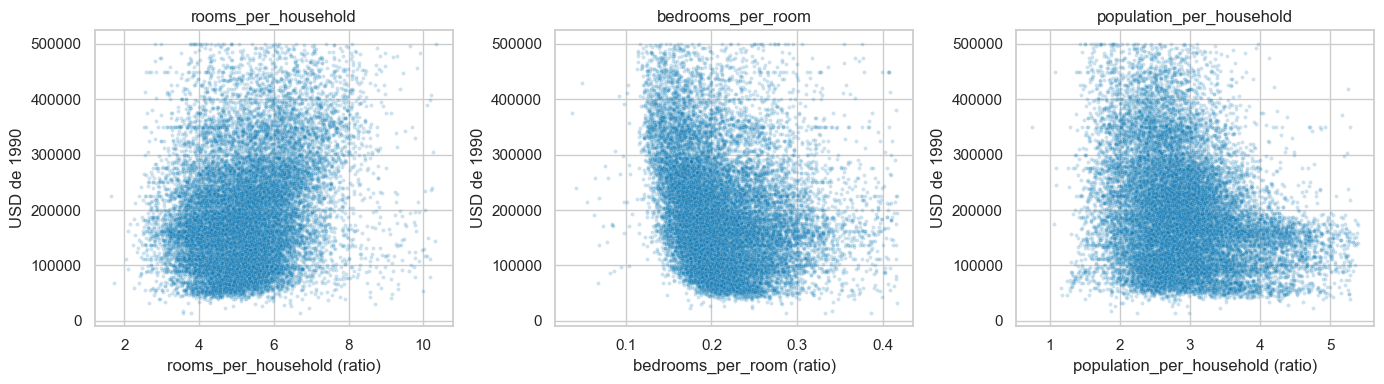

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
mapa = ejes[0].scatter(df_clean["longitude"], df_clean["latitude"], c=df_clean["median_house_value"],
                      cmap="viridis", s=5, alpha=0.55)
fig.colorbar(mapa, ax=ejes[0], label="Valor mediano (USD de 1990)")
ejes[0].set(title="Ubicación y valor de las zonas", xlabel="Longitud (grados)", ylabel="Latitud (grados)")
sns.scatterplot(data=muestra, x="rooms_per_household", y="median_house_value",
                hue="median_income", palette="viridis", alpha=0.5, s=20, ax=ejes[1])
ejes[1].set(title="Habitaciones por hogar · subconjunto curado", xlabel="Habitaciones / hogar", ylabel="USD de 1990")
mostrar()
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for columna, eje in zip(ratios, ejes):
    sns.scatterplot(data=df_clean, x=columna, y="median_house_value", alpha=0.2, s=8, ax=eje)
    eje.set(title=columna, xlabel=columna + " (ratio)", ylabel="USD de 1990")
mostrar()

### 4.2 Costa e ingreso juntos
Dividimos el ingreso en cuatro cuartiles (grupos de frecuencia aproximadamente similar).
Una tabla cruzada permite comparar costa dentro de cada nivel de ingreso. La tabla de conteos
evita interpretar grupos minúsculos como evidencia fuerte. Esto es estratificación descriptiva,
no un ajuste causal ni una regresión.

grupo_ingreso,Q1,Q2,Q3,Q4
ocean_proximity,,,,
<1H OCEAN,143450.0,179800.0,205800.0,273950.0
INLAND,74000.0,105650.0,132600.0,193800.0
ISLAND,450000.0,357350.0,NaN,NaN
NEAR BAY,126900.0,187500.0,225000.0,312500.0
NEAR OCEAN,131750.0,198400.0,237500.0,316700.0


grupo_ingreso,Q1,Q2,Q3,Q4
ocean_proximity,,,,
<1H OCEAN,1498,1951,2203,2710
INLAND,2325,1728,1331,885
ISLAND,1,4,0,0
NEAR BAY,386,505,577,594
NEAR OCEAN,562,585,659,583


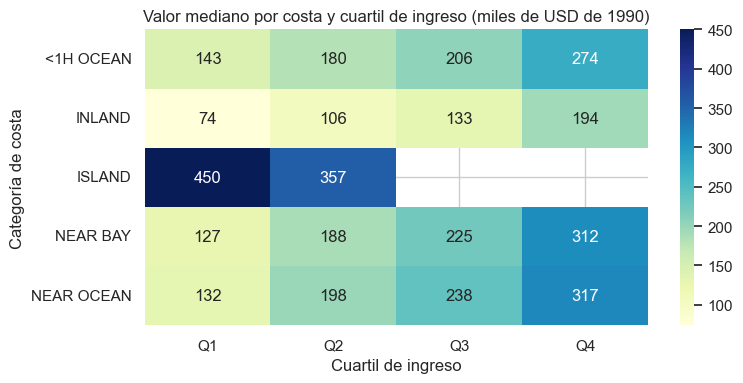

In [10]:
df_clean["grupo_ingreso"] = pd.qcut(df_clean["median_income"], q=4, labels=["Q1", "Q2", "Q3", "Q4"])
cruce = df_clean.pivot_table(index="ocean_proximity", columns="grupo_ingreso",
                       values="median_house_value", aggfunc="median", observed=True)
conteos = pd.crosstab(df_clean["ocean_proximity"], df_clean["grupo_ingreso"])
display(cruce.round(0))
display(conteos)
plt.figure(figsize=(8, 4))
sns.heatmap(cruce / 1000, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Valor mediano por costa y cuartil de ingreso (miles de USD de 1990)")
plt.xlabel("Cuartil de ingreso")
plt.ylabel("Categoría de costa")
mostrar()

### 4.3 Sensibilidad a la imputación
Recalculamos la asociación dormitorios/habitaciones vs. precio excluyendo las filas
imputadas. La comparación permite ver cuánto depende este resultado de nuestra limpieza.

In [11]:
sensibilidad = pd.Series({
    "con_imputacion": df["bedrooms_per_room"].corr(df["median_house_value"]),
    "sin_filas_imputadas": df.loc[~df["bedrooms_imputados"], ["bedrooms_per_room", "median_house_value"]].corr().iloc[0, 1],
})
display(sensibilidad.to_frame("Pearson").round(3))

,Pearson
con_imputacion,-0.233
sin_filas_imputadas,-0.256


## Conclusiones y límites
Las siguientes frases salen de los cálculos, no de cifras escritas a mano.
El análisis describe asociaciones entre zonas de 1990. No explica por sí solo precios actuales,
ni permite concluir que vivir cerca del océano cause un precio mayor.

In [12]:
resumen = {
    "filas": len(df), "imputados": int(df["bedrooms_imputados"].sum()),
    "filas_curadas": len(df_clean), "excluidas": len(df) - len(df_clean),
    "porcentaje_excluido": (len(df) - len(df_clean)) / len(df) * 100,
    "cortes_p99": cortes_p99.to_dict(),
    "pearson_ingreso_precio_curado": float(corr_clean.loc["median_income", "median_house_value"]),
    "mediana_precio": float(df["median_house_value"].median()),
    "pearson_ingreso_precio": float(df["median_income"].corr(df["median_house_value"])),
    "spearman_ingreso_precio": float(df[["median_income", "median_house_value"]].corr(method="spearman").iloc[0, 1]),
    "maximo_precio": float(df["median_house_value"].max()),
    "porcentaje_en_maximo": float(df["median_house_value"].eq(df["median_house_value"].max()).mean() * 100),
    "medianas_costa": por_costa["median"].to_dict(),
    "conteos_costa": por_costa["count"].to_dict(),
}
display(Markdown(f"""
- Se analizaron **{len(df):,} zonas**; se imputaron **{resumen['imputados']}** dormitorios faltantes.
- La mediana del valor por zona es **USD {resumen['mediana_precio']:,.0f}** de 1990.
- Ingreso y precio tienen Pearson **{resumen['pearson_ingreso_precio']:.3f}** y Spearman **{resumen['spearman_ingreso_precio']:.3f}**: asociación positiva, no causalidad.
- **{resumen['porcentaje_en_maximo']:.2f}%** de las zonas están en el máximo observado de USD **{resumen['maximo_precio']:,.0f}**. El posible tope limita el análisis de viviendas caras.
- El subconjunto curado conserva **{len(df_clean):,} zonas** y excluye **{len(df) - len(df_clean):,} ({resumen['porcentaje_excluido']:.2f}%)**: precio en el máximo o algún ratio por encima de P99.
- En ese subconjunto ingreso/precio tienen Pearson **{resumen['pearson_ingreso_precio_curado']:.3f}**. No describe ya a todas las zonas originales.
- En el curado, INLAND tiene mediana **USD {por_costa.loc['INLAND', 'median']:,.0f}** y NEAR OCEAN **USD {por_costa.loc['NEAR OCEAN', 'median']:,.0f}**. Se compara con sus conteos y el cruce por ingreso.
- El mapa aporta contexto espacial, pero no mide distancia exacta ni calidad del barrio.
"""))


- Se analizaron **20,640 zonas**; se imputaron **207** dormitorios faltantes.
- La mediana del valor por zona es **USD 179,700** de 1990.
- Ingreso y precio tienen Pearson **0.688** y Spearman **0.677**: asociación positiva, no causalidad.
- **4.68%** de las zonas están en el máximo observado de USD **500,001**. El posible tope limita el análisis de viviendas caras.
- El subconjunto curado conserva **19,087 zonas** y excluye **1,553 (7.52%)**: precio en el máximo o algún ratio por encima de P99.
- En ese subconjunto ingreso/precio tienen Pearson **0.653**. No describe ya a todas las zonas originales.
- En el curado, INLAND tiene mediana **USD 107,200** y NEAR OCEAN **USD 219,500**. Se compara con sus conteos y el cruce por ingreso.
- El mapa aporta contexto espacial, pero no mide distancia exacta ni calidad del barrio.
